# Day-ahead forecast of hourly bike demand

**Goal:** every evening, forecast how many bikes will be rented in each hour of the next day, so the operator can move bikes to where they will be needed before the demand arrives.

This notebook replaces the v1 model (`old/XGBoost_Count.ipynb`). What changed and why:

| v1 | v2 (this notebook) | Why |
|---|---|---|
| Dates read month-first | Dates read with the file's day-first format | v1 put the wrong month on 35% of rows and the wrong weekend flag on 14% |
| Random 80:20 split | Train Dec 2017 – Sep 2018, test Oct – Nov 2018 | A forecast has to work on future days; a random split lets the model learn from the hours either side of each test hour |
| Optuna scored on the test set | Optuna scored on monthly folds inside the training period | Choosing settings by their test score makes that score optimistic |
| No baseline | Naive and linear baselines | A score means little without a simple alternative to beat |
| Weather and calendar only | Plus demand on previous days and recent rain | Yesterday's demand is already known when tomorrow's forecast is made |
| Single-number forecast | Plus 90% prediction intervals | Planners need a range, not just one number |
| Built-in feature importance | SHAP explanations | Shows how each input pushes an individual forecast up or down |

**Assumption.** The dataset has observed weather, not weather forecasts, so observed weather stands in for a forecast. Section 9 measures how much worse the model gets with realistic forecast errors.

Run `N_TRIALS=10 jupyter nbconvert --execute ...` for a quick pass; the default is 100 Optuna trials per model.

In [1]:
import os
import time

try:
    import bikeshare  # noqa: F401
except ModuleNotFoundError:  # running without `pip install -e .`
    import sys
    sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from IPython.display import Markdown, display
from sklearn.model_selection import KFold, train_test_split

from bikeshare import data, evaluate, features, models, plotting, serving, validation

N_TRIALS = int(os.environ.get("N_TRIALS", 100))
REPORTS = plotting.FIGURES.parent
plotting.use_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)


def show(table, cols=("MAE", "RMSE", "R2")):
    return table[list(cols)].round({"MAE": 1, "RMSE": 1, "R2": 3, "R2_sqrt": 3})


hourly = data.load()
frame = features.build(hourly)
y = frame["rentals"]
X = frame[features.FEATURES]
train_idx, test_idx = validation.train_test_split_by_time(frame)
folds = validation.rolling_origin_folds(frame)

print(f"{len(frame):,} open hours: {len(train_idx):,} for training (Dec 2017 - Sep 2018), "
      f"{len(test_idx):,} for the final test (Oct - Nov 2018)")
pd.DataFrame([{"validation month": frame.loc[v, "timestamp"].min().strftime("%b %Y"),
               "training hours": len(t), "validation hours": len(v)} for t, v in folds])

8,465 open hours: 7,152 for training (Dec 2017 - Sep 2018), 1,313 for the final test (Oct - Nov 2018)


,validation month,training hours,validation hours
0,Jun 2018,4320,720
1,Jul 2018,5040,744
2,Aug 2018,5784,744
3,Sep 2018,6528,624


## 1. How much did the v1 problems matter?

Three v1 problems, each measured with v1's own model (XGBoost with default settings and a square-root target):

1. **Date bug.** The file stores 1 Dec 2017 as `01/12/17`; v1 read it as 12 Jan 2017.
2. **Random split.** Test hours sit between training hours from the same days, so the test is much easier than forecasting a future day.
3. **Tuning on the test set.** Optuna picked the settings with the best test score, then reported that score.

In [2]:
# Re-create v1's month and weekend columns exactly as v1 parsed the dates
raw_dates = pd.read_csv(data.DATA_PATH, usecols=["Date"])["Date"]
assert (pd.to_datetime(raw_dates, format="%d/%m/%y") == hourly["date"]).all()  # same row order
v1_dates = raw_dates.apply(pd.to_datetime)

frame_v1 = frame.copy()
frame_v1["month"] = v1_dates.dt.month.loc[frame.index]
frame_v1["is_weekend"] = (v1_dates.dt.weekday >= 5).astype(int).loc[frame.index]
print(f"rows with the wrong month: {(frame_v1['month'] != frame['month']).mean():.0%}, "
      f"wrong weekend flag: {(frame_v1['is_weekend'] != frame['is_weekend']).mean():.0%}")

rand_train, rand_test = (pd.Index(i) for i in train_test_split(frame.index, test_size=0.2, random_state=42))


def fit_score(source, cols, tr, te, model=None):
    model = models.sqrt_target(models.xgb()) if model is None else model
    model.fit(source.loc[tr, cols], y.loc[tr])
    return evaluate.metrics(y.loc[te], model.predict(source.loc[te, cols]))


v1_checks = pd.DataFrame({
    "v1 as written (date bug), random split": fit_score(frame_v1, features.V1_FEATURES, rand_train, rand_test),
    "date bug fixed, random split": fit_score(frame, features.V1_FEATURES, rand_train, rand_test),
    "date bug fixed, future months (Oct-Nov)": fit_score(frame, features.V1_FEATURES, train_idx, test_idx),
}).T
show(v1_checks, ("R2_sqrt", "R2", "MAE", "RMSE"))

rows with the wrong month: 35%, wrong weekend flag: 14%


,R2_sqrt,R2,MAE,RMSE
"v1 as written (date bug), random split",0.906,0.892,117.7,205.7
"date bug fixed, random split",0.930,0.925,94.1,172.0
"date bug fixed, future months (Oct-Nov)",0.696,0.651,239.8,331.6


`R2_sqrt` is R² on the square-root scale, the number v1 reported (90.74% before tuning). `R2` and the errors are in bikes.

**Tuning on the test set.** One Optuna search over v1's search space scores every trial two ways: 3-fold cross-validation on the training rows, and the test rows. v1's method keeps the trial with the best *test* score. The honest method keeps the trial with the best *cross-validation* score and only then looks at its test score.

In [3]:
def v1_space(trial):  # v1's search space, with the deprecated Optuna calls updated
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
    }


inner_folds = list(KFold(3, shuffle=True, random_state=0).split(rand_train))


def v1_objective(trial):
    params = v1_space(trial)
    cv_r2 = [fit_score(frame_v1, features.V1_FEATURES, rand_train[a], rand_train[b],
                       models.sqrt_target(models.xgb(**params)))["R2_sqrt"] for a, b in inner_folds]
    test_r2 = fit_score(frame_v1, features.V1_FEATURES, rand_train, rand_test, models.sqrt_target(models.xgb(**params)))
    trial.set_user_attr("test_r2", test_r2["R2_sqrt"])
    return float(np.mean(cv_r2))


study_v1 = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=models.SEED))
study_v1.optimize(v1_objective, n_trials=max(10, N_TRIALS // 2))
v1_trials = study_v1.trials_dataframe()
picked_on_test = v1_trials["user_attrs_test_r2"].max()
picked_on_cv = v1_trials.loc[v1_trials["value"].idxmax(), "user_attrs_test_r2"]
print(f"{len(v1_trials)} trials")
print(f"v1 method, best test score among trials:          test R2_sqrt {picked_on_test:.2%}")
print(f"honest method, best cross-validation score first: test R2_sqrt {picked_on_cv:.2%}")

50 trials
v1 method, best test score among trials:          test R2_sqrt 92.11%
honest method, best cross-validation score first: test R2_sqrt 92.05%


**What this shows.**

- **The date bug cost about 2.4 points.** Fixing it alone lifts v1's R² from 90.6% to 93.0% (square-root scale), with no other change.
- **The random split hid the most.** The same date-fixed model drops to 69.6% when it has to forecast October and November, and its average error rises from 94 to 240 bikes per hour.
- **Tuning on the test set mattered least.** The trial with the best test score reached 92.11%; the trial picked by cross-validation reached 92.05%, a gap of under 0.1 points.

So v1's 92% headline came mostly from the random split, not from the tuning.

## 2. Baselines and feature groups

Sections 2 to 4 use only the training period. Each model is trained on the months before a validation month, scored on that month (June, July, August and September 2018), and the four scores are averaged. The test months stay unseen.

- **Naive baselines** copy past demand: the same hour yesterday, the same hour last week, or that hour's average over the last 7 days.
- **Ridge regression**: a linear model with a one-hot hour-of-week profile plus the weather and lag features.
- **XGBoost** with default settings, on growing feature sets.

In [4]:
def cv_row(name, make_model, cols):
    scores, _ = models.cross_validate(make_model, frame[cols], y, folds)
    return {"model": name, **scores.mean().to_dict()}


def naive_row(name, column):
    scores = [evaluate.metrics(y.loc[v], models.naive(frame.loc[v], column)) for _, v in folds]
    return {"model": name, **pd.DataFrame(scores).mean().to_dict()}


xgb_default = lambda: models.sqrt_target(models.xgb())  # noqa: E731
ridge_numeric = ["is_holiday", *features.WEATHER, *features.RECENT_RAIN, *features.LAGS]
ridge_cols = features.FEATURES + ["hour_weekend"]
feature_sets = {
    "v1 features (date fixed)": features.V1_FEATURES,
    "calendar + weather": features.CALENDAR + features.WEATHER,
    "calendar + lags, no weather": features.CALENDAR + features.LAGS,
    "calendar + weather + lags": features.CALENDAR + features.WEATHER + features.LAGS,
    "+ recent rain (final set)": features.FEATURES,
}
rows = [
    naive_row("naive: same hour yesterday", "lag_24h"),
    naive_row("naive: same hour last week", "lag_168h"),
    naive_row("naive: same-hour 7-day mean", "same_hour_7d_mean"),
    cv_row("Ridge, final features", lambda: models.sqrt_target(models.ridge(ridge_numeric)), ridge_cols),
]
rows += [cv_row(f"XGBoost, {name}", xgb_default, cols) for name, cols in feature_sets.items()]
baseline_cv = pd.DataFrame(rows).set_index("model")
show(baseline_cv)

,MAE,RMSE,R2
model,,,
naive: same hour yesterday,314.8,523.0,0.405
naive: same hour last week,327.3,568.6,0.279
naive: same-hour 7-day mean,289.0,441.8,0.570
"Ridge, final features",282.9,382.4,0.669
"XGBoost, v1 features (date fixed)",220.6,315.2,0.780
"XGBoost, calendar + weather",226.2,322.1,0.769
"XGBoost, calendar + lags, no weather",390.9,597.9,0.194
"XGBoost, calendar + weather + lags",203.0,294.2,0.808
"XGBoost, + recent rain (final set)",189.1,278.9,0.829


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


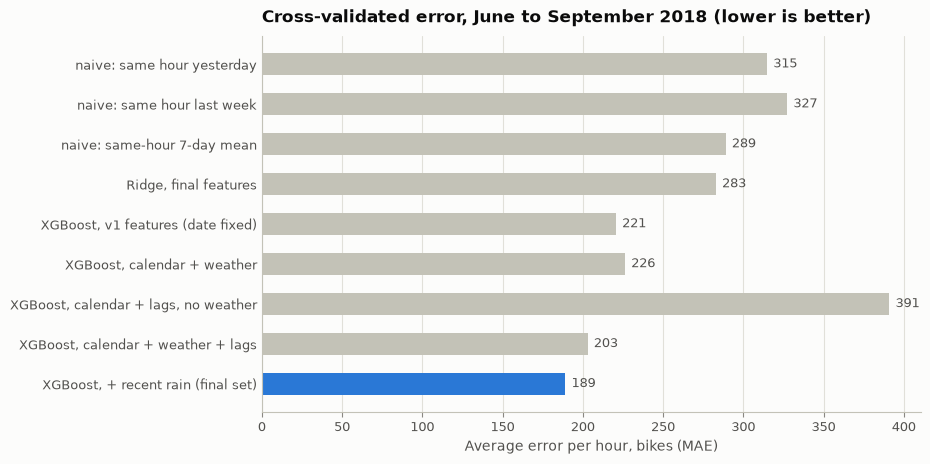

In [5]:
def bar_compare(table, highlight, title, xlabel="Average error per hour, bikes (MAE)"):
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(table) + 1.1))
    colors = [plotting.BLUE if name == highlight else plotting.CONTEXT for name in table.index]
    ax.barh(table.index, table["MAE"], height=0.55, color=colors)
    for i, value in enumerate(table["MAE"]):
        ax.text(value + table["MAE"].max() * 0.01, i, f"{value:.0f}", va="center", fontsize=9, color=plotting.INK_2)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return fig


bar_compare(baseline_cv, "XGBoost, + recent rain (final set)",
            "Cross-validated error, June to September 2018 (lower is better)")
plt.show()

- **Weather is essential.** Without it (calendar and lags only) the error is 391 bikes per hour, worse than every naive baseline.
- **Lags add to weather.** Adding the last week's demand cuts the error from 226 to 203.
- **Recent rain adds again.** Rain in the previous 3 hours cuts it to 189: people stay off bikes for a while after the rain stops.
- **Month is left out.** With only one year of data, October and November never appear in the training months, so the model cannot learn what they mean.
- **Ridge regression** (283) beats the naive baselines (289 to 327) but is far behind the boosted trees.

## 3. Target transform and loss

Hourly counts are right-skewed (skew 1.14), and v1 trained on the square root of the count. Here that choice is checked against the raw count, log(1 + count), and Poisson and Tweedie losses (built for count data), for both XGBoost and LightGBM, all with default settings.

In [6]:
losses = {
    "XGBoost, raw count": lambda: models.xgb(),
    "XGBoost, log(1 + count)": lambda: models.log_target(models.xgb()),
    "XGBoost, Poisson loss": lambda: models.xgb(objective="count:poisson"),
    "XGBoost, square root": lambda: models.sqrt_target(models.xgb()),
    "LightGBM, Poisson loss": lambda: models.lgbm(objective="poisson"),
    "LightGBM, Tweedie loss": lambda: models.lgbm(objective="tweedie"),
    "LightGBM, square root": lambda: models.sqrt_target(models.lgbm()),
}
loss_cv = pd.DataFrame([cv_row(name, make, features.FEATURES) for name, make in losses.items()]).set_index("model")
show(loss_cv)

,MAE,RMSE,R2
model,,,
"XGBoost, raw count",207.4,299.9,0.803
"XGBoost, log(1 + count)",201.2,297.8,0.805
"XGBoost, Poisson loss",190.3,281.1,0.827
"XGBoost, square root",189.1,278.9,0.829
"LightGBM, Poisson loss",181.2,268.1,0.842
"LightGBM, Tweedie loss",177.1,264.3,0.847
"LightGBM, square root",176.0,259.9,0.852


The square-root target is the best option for both libraries, so v1's choice stands. LightGBM beats XGBoost at default settings (176 vs 189), and both go on to tuning.

## 4. Tuning on the monthly folds

Both boosters are tuned with Optuna on the square-root target: 100 trials each, seeded so the search repeats exactly, minimising the average RMSE over the four monthly folds. Trials that are worse than the median after the first folds are stopped early (pruned).

A single model is kept unless averaging the two improves the cross-validated RMSE by more than 2%, because one model is simpler to explain and to serve.

In [7]:
build_xgb = lambda **p: models.sqrt_target(models.xgb(**p))  # noqa: E731
build_lgbm = lambda **p: models.sqrt_target(models.lgbm(**p))  # noqa: E731

start = time.time()
studies = {
    "XGBoost, tuned": models.tune(build_xgb, models.xgb_space, X, y, folds, n_trials=N_TRIALS),
    "LightGBM, tuned": models.tune(build_lgbm, models.lgbm_space, X, y, folds, n_trials=N_TRIALS),
}
print(f"{2 * N_TRIALS} trials in {time.time() - start:.0f}s; "
      f"pruned: {sum(t.state.name == 'PRUNED' for s in studies.values() for t in s.trials)}")

tuned = {
    "XGBoost, tuned": lambda: build_xgb(**studies["XGBoost, tuned"].best_params),
    "LightGBM, tuned": lambda: build_lgbm(**studies["LightGBM, tuned"].best_params),
}
cv_scores, oof = {}, {}
for name, make in tuned.items():
    cv_scores[name], oof[name] = models.cross_validate(make, X, y, folds)
oof["average of both"] = (oof["XGBoost, tuned"] + oof["LightGBM, tuned"]) / 2
cv_scores["average of both"] = pd.DataFrame(
    [evaluate.metrics(y.loc[v], oof["average of both"].loc[v]) for _, v in folds])

tuned_cv = pd.DataFrame({name: s.mean() for name, s in cv_scores.items()}).T
best_single = tuned_cv.loc[list(tuned), "RMSE"].idxmin()
gain = 1 - tuned_cv.loc["average of both", "RMSE"] / tuned_cv.loc[best_single, "RMSE"]
final_name = "average of both" if gain > 0.02 else best_single
print(f"best single model: {best_single}; averaging changes CV RMSE by {gain:.1%} -> keep {final_name}")
show(tuned_cv)

200 trials in 243s; pruned: 104


best single model: LightGBM, tuned; averaging changes CV RMSE by -0.4% -> keep LightGBM, tuned


,MAE,RMSE,R2
"XGBoost, tuned",179.4,262.5,0.849
"LightGBM, tuned",173.1,255.2,0.857
average of both,174.3,256.3,0.856


In [8]:
pd.Series(studies[final_name].best_params, name="best settings").to_frame()

,best settings
n_estimators,863.000000
learning_rate,0.043624
num_leaves,12.000000
min_child_samples,7.000000
subsample,0.701654
colsample_bytree,0.635659
reg_alpha,0.002271
reg_lambda,0.073538


## 5. Final test: October and November 2018

The chosen model is retrained on all training months (Dec 2017 to Sep 2018) and scored once on the two test months. The baselines and the v1 approach are scored on exactly the same hours.

In [9]:
final_model = tuned[final_name]().fit(X.loc[train_idx], y.loc[train_idx])
test = frame.loc[test_idx, ["timestamp", "date", "hour", "is_weekend", "is_holiday", "rainfall", "rentals"]].copy()
test["forecast"] = final_model.predict(X.loc[test_idx])


def trained_on_train(model, source, cols):
    return model.fit(source.loc[train_idx, cols], y.loc[train_idx]).predict(source.loc[test_idx, cols])


predictions = {
    "naive: same hour yesterday": models.naive(frame.loc[test_idx], "lag_24h"),
    "naive: same-hour 7-day mean": models.naive(frame.loc[test_idx], "same_hour_7d_mean"),
    "Ridge regression": trained_on_train(models.sqrt_target(models.ridge(ridge_numeric)), frame, ridge_cols),
    "v1 as written (date bug)": trained_on_train(models.sqrt_target(models.xgb()), frame_v1, features.V1_FEATURES),
    "v1 with dates fixed": trained_on_train(models.sqrt_target(models.xgb()), frame, features.V1_FEATURES),
    f"v2: {final_name}": test["forecast"],
}
test_table = pd.DataFrame({name: evaluate.metrics(test["rentals"], p) for name, p in predictions.items()}).T
final_row = test_table.loc[f"v2: {final_name}"]
for ref in ["naive: same hour yesterday", "v1 as written (date bug)"]:
    print(f"vs {ref}: MAE {test_table.loc[ref, 'MAE']:.0f} -> {final_row['MAE']:.0f} bikes per hour "
          f"({1 - final_row['MAE'] / test_table.loc[ref, 'MAE']:.0%} lower)")
show(test_table, ("MAE", "RMSE", "R2", "R2_sqrt"))

vs naive: same hour yesterday: MAE 231 -> 139 bikes per hour (40% lower)
vs v1 as written (date bug): MAE 253 -> 139 bikes per hour (45% lower)


,MAE,RMSE,R2,R2_sqrt
naive: same hour yesterday,231.0,404.2,0.481,0.378
naive: same-hour 7-day mean,233.8,377.0,0.549,0.497
Ridge regression,170.1,248.3,0.804,0.793
v1 as written (date bug),252.5,354.8,0.601,0.657
v1 with dates fixed,239.8,331.6,0.651,0.696
"v2: LightGBM, tuned",139.4,213.2,0.856,0.884


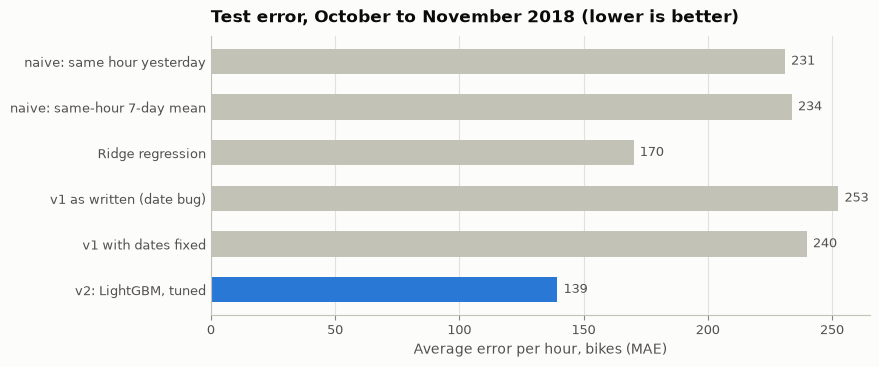

In [10]:
bar_compare(test_table, f"v2: {final_name}", "Test error, October to November 2018 (lower is better)")
plotting.save(plt.gcf(), "test_error_by_model")
plt.show()

On the two unseen months, the tuned LightGBM model misses by **139 bikes per hour** on average: 40% less than copying yesterday's numbers (231) and 45% less than v1 as written (253). R² is 0.86 in bikes (0.88 on v1's square-root scale).

- **Ridge regression with the same features (170) already beats v1's XGBoost (240).** The features and the validation set-up matter more than the choice of algorithm.
- **The test error (139) is lower than the cross-validated error (173)** because the validation months are mostly summer, the busiest season, and errors grow with demand. Compare models within one table, not across tables.

## 6. 90% prediction intervals

Split conformal prediction: take the model's out-of-fold errors from the validation months, find the error size that covers 90% of them, and put that margin around each forecast. The margin is set on the square-root scale, so the range widens as demand grows. Nothing here assumes the errors are normal; what matters is how often the real value lands inside.

One margin for every hour can be right on average but too narrow at the busiest hours, which are the ones that matter for moving bikes. To check this inside the training period, margins are calibrated on June to August and checked on September, either as one margin for all hours or separately for each of ten time bands (weekday or weekend/holiday, times night, morning peak, daytime, evening peak and late evening).

In [11]:
final_oof = oof[final_name]
bands = features.time_band(frame)
calib = final_oof.index[frame.loc[final_oof.index, "timestamp"] < "2018-09-01"]
check = final_oof.index.difference(calib)


def inside(idx, lower, upper):
    return pd.Series((y.loc[idx].to_numpy() >= lower) & (y.loc[idx].to_numpy() <= upper), index=idx)


q_one = evaluate.conformal_quantile(y.loc[calib], final_oof.loc[calib])
q_bands = evaluate.conformal_quantiles(y.loc[calib], final_oof.loc[calib], bands.loc[calib])
one = inside(check, *evaluate.prediction_interval(final_oof.loc[check], q_one))
per_band = inside(check, *evaluate.prediction_interval(final_oof.loc[check], bands.loc[check].map(q_bands)))
september = pd.DataFrame({"one margin": one.groupby(bands.loc[check]).mean(),
                          "margin per band": per_band.groupby(bands.loc[check]).mean()})
september.loc["all hours"] = [one.mean(), per_band.mean()]
september.round(3)

,one margin,margin per band
weekday daytime,0.895,0.857
weekday evening peak,0.883,0.983
weekday late evening,0.822,0.867
weekday morning peak,0.889,0.911
weekday night,0.962,0.943
weekend/holiday daytime,0.935,0.948
weekend/holiday evening peak,0.886,0.977
weekend/holiday late evening,0.758,0.848
weekend/holiday morning peak,0.909,0.909
weekend/holiday night,1.000,0.961


In September, one margin covers 91% of hours overall, but only 88% of weekday evening peaks and 76% of weekend and holiday late evenings, while night hours are over-covered (96 to 100%). Margins per band lift the four peak bands to 91 to 98% with similar overall coverage (92%), so per-band margins are used. Weekday daytime gets a little worse (90% to 86%). That trade is worth it, because peaks are when bikes run out.

target 90% | margin per band: coverage 93.4%, average width 700 bikes
           | one margin:      coverage 90.9%, average width 683 bikes


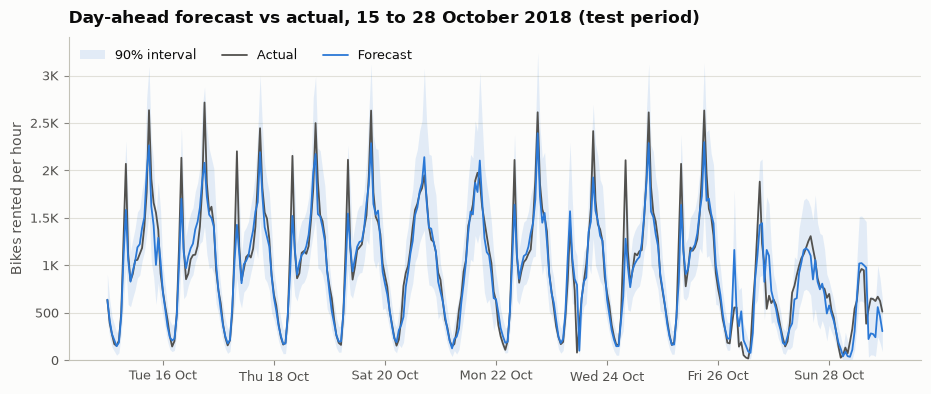

In [12]:
q_by_band = evaluate.conformal_quantiles(y.loc[final_oof.index], final_oof, bands.loc[final_oof.index])
q_single = evaluate.conformal_quantile(y.loc[final_oof.index], final_oof)
test["band"] = bands.loc[test_idx]
test["lower"], test["upper"] = evaluate.prediction_interval(test["forecast"], test["band"].map(q_by_band))
test["inside"] = (test["rentals"] >= test["lower"]) & (test["rentals"] <= test["upper"])
one_lower, one_upper = evaluate.prediction_interval(test["forecast"], q_single)
test["inside_one_margin"] = (test["rentals"] >= one_lower) & (test["rentals"] <= one_upper)
test_coverage = test["inside"].mean()
print(f"target 90% | margin per band: coverage {test_coverage:.1%}, "
      f"average width {(test['upper'] - test['lower']).mean():.0f} bikes")
print(f"           | one margin:      coverage {test['inside_one_margin'].mean():.1%}, "
      f"average width {(one_upper - one_lower).mean():.0f} bikes")

window = test.set_index("timestamp").reindex(pd.date_range("2018-10-15", "2018-10-28 23:00", freq="h"))
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(window.index, window["lower"], window["upper"], color=plotting.BLUE, alpha=0.12, linewidth=0,
                label="90% interval")
ax.plot(window.index, window["rentals"], color=plotting.INK_2, linewidth=1.3, label="Actual")
ax.plot(window.index, window["forecast"], color=plotting.BLUE, linewidth=1.3, label="Forecast")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
ax.yaxis.set_major_formatter(plotting.thousands)
ax.set_ylabel("Bikes rented per hour")
ax.set_ylim(bottom=0)
ax.set_title("Day-ahead forecast vs actual, 15 to 28 October 2018 (test period)")
ax.legend(loc="upper left", ncols=3)
plotting.save(fig, "forecast_vs_actual")
plt.show()

On the test months the per-band intervals cover **93.4%** of hours (target 90%), with an average width of 700 bikes; one margin would cover 90.9% at 683 bikes. The chart shows the main weakness: the weekday 8 am peak is regularly under-forecast.

## 7. Where the errors are

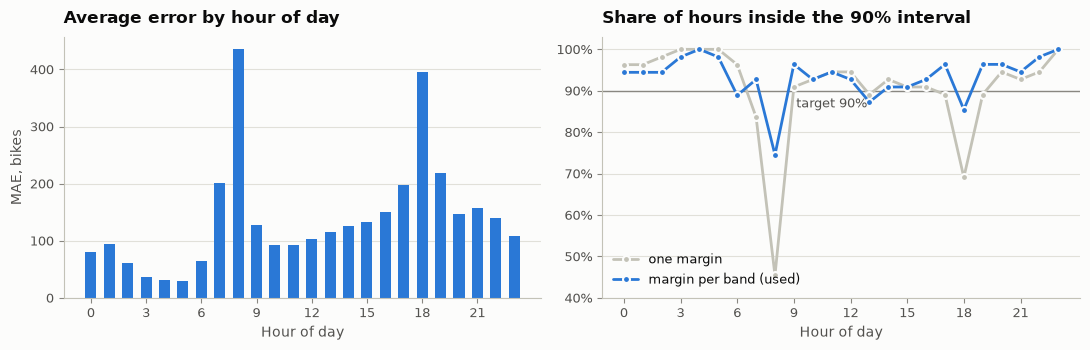

,hours,MAE,coverage
holiday,24,292.275,0.875
weekday,936,141.782,0.932
weekend,353,122.828,0.943


In [13]:
test["abs_error"] = (test["rentals"] - test["forecast"]).abs()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
mae_by_hour = test.groupby("hour")["abs_error"].mean()
axes[0].bar(mae_by_hour.index, mae_by_hour.values, width=0.6, color=plotting.BLUE)
axes[0].set_title("Average error by hour of day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MAE, bikes")
axes[1].axhline(0.9, color=plotting.MUTED, linewidth=1)
for column, color, label in [("inside_one_margin", plotting.CONTEXT, "one margin"),
                             ("inside", plotting.BLUE, "margin per band (used)")]:
    by_hour = test.groupby("hour")[column].mean()
    axes[1].plot(by_hour.index, by_hour.values, color=color, marker="o", markersize=5, label=label,
                 markeredgecolor=plotting.SURFACE, markeredgewidth=1.5)
axes[1].annotate("target 90%", (11, 0.9), xytext=(0, -12), textcoords="offset points", ha="center", fontsize=9,
                 color=plotting.INK_2)
axes[1].legend(loc="lower left")
axes[1].set_ylim(0.4, 1.03)
axes[1].yaxis.set_major_formatter(plotting.percent)
axes[1].set_title("Share of hours inside the 90% interval")
axes[1].set_xlabel("Hour of day")
for ax in axes:
    ax.set_xticks(range(0, 24, 3))
fig.tight_layout()
plotting.save(fig, "error_and_coverage_by_hour")
plt.show()

kind_of_day = np.select([test["is_holiday"] == 1, test["is_weekend"] == 1], ["holiday", "weekend"], "weekday")
test.groupby(kind_of_day).agg(hours=("abs_error", "size"), MAE=("abs_error", "mean"),
                              coverage=("inside", "mean")).round(3)

In [14]:
daily = test.groupby("date").agg(actual=("rentals", "sum"), forecast=("forecast", "sum"),
                                 MAE=("abs_error", "mean"), rain_mm=("rainfall", "sum"),
                                 holiday=("is_holiday", "max"), open_hours=("rentals", "size"))
daily["daily_error_%"] = (daily["forecast"] / daily["actual"] - 1) * 100
daily.sort_values("MAE", ascending=False).head(6).round(1)

,actual,forecast,MAE,rain_mm,holiday,open_hours,daily_error_%
date,,,,,,,
2018-10-03,30349,23753.5,292.3,0.0,1,24,-21.7
2018-10-10,24410,22426.2,286.1,7.0,0,24,-8.1
2018-10-01,27909,23757.3,262.1,0.0,0,24,-14.9
2018-10-07,27614,23491.7,240.6,0.0,0,24,-14.9
2018-11-18,14319,9356.0,214.4,0.0,0,24,-34.7
2018-10-26,13377,15361.7,197.5,11.0,0,24,14.8


- **Errors cluster at the commuting peaks:** about 435 bikes at 8 am and 395 at 6 pm, against under 100 in the night hours.
- **Per-band margins help but do not fully fix the peaks.** Coverage at 8 am rises from 46% to 75%, and at 6 pm from 69% to 85%. The morning peak stays below target because the model under-forecasts it.
- **Four of the six worst days follow a closed day.** 1, 3, 7 and 10 October come right after the closures on 30 September and 2, 6 (partly) and 9 October, when yesterday's demand is unknown, and all four are under-forecast by 8 to 22%. The other two are a rainy Friday and a Sunday in mid-November.
- **Holidays are hard:** holiday hours have twice the weekday error (292 vs 142). With 18 holidays in a year, there is little to learn from.

**Tried and rejected: like-for-like lags.** The weekday 8 am peak is under-forecast in the validation months too, not only in the test months. Two extra features were tried to fix it: demand at the same hour on the previous day of the same type (weekday, or weekend/holiday), and its 5-day mean. They are judged on the validation months only, with the tuned settings.

In [15]:
full = features.add_features(hourly)
day_type = (full["is_weekend"] | full["is_holiday"]).astype(int)
by_type = full["rentals"].where(full["functioning"]).groupby([day_type, full["hour"]])
extra = pd.DataFrame({
    "same_type_lag": by_type.shift(1),
    "same_type_5d_mean": by_type.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()),
}).loc[frame.index]
with_extra = frame.join(extra)
weekday_8am = (frame["hour"] == 8) & (day_type.loc[frame.index] == 0)
rows = []
for label, cols in [("final features", features.FEATURES), ("+ like-for-like lags", features.FEATURES + list(extra))]:
    scores, pred = models.cross_validate(tuned[final_name], with_extra[cols], y, folds)
    bias = (pred - y.loc[pred.index])[weekday_8am.loc[pred.index]].mean()
    rows.append({"features": label, "MAE": scores["MAE"].mean(), "RMSE": scores["RMSE"].mean(),
                 "weekday 8am bias (bikes)": bias})
pd.DataFrame(rows).set_index("features").round(1)

,MAE,RMSE,weekday 8am bias (bikes)
features,,,
final features,173.1,255.2,-159.9
+ like-for-like lags,179.5,270.4,-166.7


The extra features made the cross-validated error worse (MAE 173 to 180, RMSE 255 to 270) and did not shrink the 8 am shortfall (-160 to -167 bikes), so they were left out. The morning-peak shortfall stays as a known limitation.

## 8. What drives the forecasts (SHAP)

SHAP splits each forecast into a contribution from every input. The values are on the model's square-root scale, so they show direction and relative size rather than bikes.

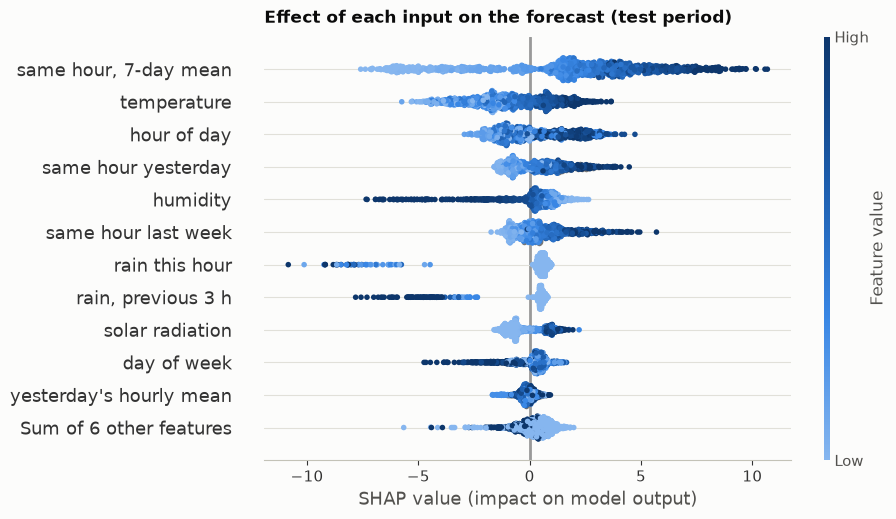

In [16]:
explainer = shap.TreeExplainer(final_model.regressor_)
raw_explanation = explainer(X.loc[test_idx])
explanation = shap.Explanation(raw_explanation.values, raw_explanation.base_values, raw_explanation.data,
                               feature_names=[features.LABELS[f] for f in features.FEATURES])
shap.plots.beeswarm(explanation, max_display=12, color=plotting.ORDINAL, show=False, plot_size=(8.5, 5.5))
plt.title("Effect of each input on the forecast (test period)", loc="left")
plotting.save(plt.gcf(), "shap_summary")
plt.show()

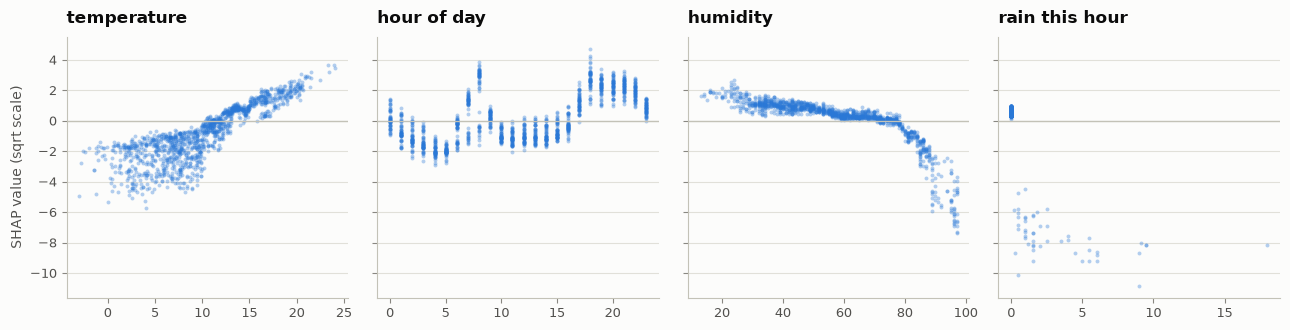

In [17]:
importance = pd.Series(np.abs(raw_explanation.values).mean(0), index=features.FEATURES).sort_values(ascending=False)
top = [f for f in importance.index if f not in features.LAGS][:4]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, name in zip(axes, top):
    ax.scatter(X.loc[test_idx, name], raw_explanation[:, name].values, s=8, color=plotting.BLUE, alpha=0.35,
               linewidths=0)
    ax.axhline(0, color=plotting.AXIS, linewidth=1)
    ax.set_title(features.LABELS[name])
axes[0].set_ylabel("SHAP value (sqrt scale)")
fig.tight_layout()
plotting.save(fig, "shap_dependence")
plt.show()

- **Recent demand at the same hour sets the baseline.** The 7-day same-hour mean is the strongest input, followed by temperature.
- **Temperature pushes forecasts up steadily** from around 0 °C to the warmest test hours (about 25 °C).
- **Rain has the biggest single effects.** Any rain this hour, or in the previous 3 hours, pulls the forecast down sharply.
- **Humidity above about 80% pulls the forecast down.** This matches the hypothesis-test results.
- **The hour-of-day effect shows the 8 am and 6 pm commuting peaks.**

## 9. How much does the weather assumption matter?

The model was given the weather that actually happened, but a live system only has a forecast. Three rough scenarios for the test months, applied to the same trained model (20 random draws each, results averaged):

1. **Typical forecast errors:** each day's temperature is off by a random amount (standard deviation 1.5 °C), humidity by 8 points and wind by 0.5 m/s. Rain is still known hour by hour.
2. **Typical errors, rain spread over the day:** as 1, but each day's rain total is spread evenly over its 24 hours, as if the forecast knew how much rain would fall but not when.
3. **Typical errors, no rain information:** as 1, but rainfall set to zero everywhere.

These error sizes are assumptions, not measurements of a real forecast service, so read the result as a sensitivity check.

In [18]:
weather_cols = ["temperature", "humidity", "wind_speed", "rainfall"]
is_test_hour = hourly["timestamp"] >= validation.TEST_START


def degraded_inputs(scenario, seed):
    rng = np.random.default_rng(seed)
    h = hourly.copy()
    h[weather_cols] = h[weather_cols].astype(float)
    days = h.loc[is_test_hour, "date"]
    unique_days = days.unique()

    def daily_offset(sd):
        return pd.Series(rng.normal(0, sd, len(unique_days)), index=unique_days).reindex(days).to_numpy()

    h.loc[is_test_hour, "temperature"] += daily_offset(1.5)
    h.loc[is_test_hour, "humidity"] = (h.loc[is_test_hour, "humidity"] + daily_offset(8)).clip(0, 100)
    h.loc[is_test_hour, "wind_speed"] = (h.loc[is_test_hour, "wind_speed"] + daily_offset(0.5)).clip(lower=0)
    if scenario == 2:
        h.loc[is_test_hour, "rainfall"] = h.loc[is_test_hour].groupby("date")["rainfall"].transform("mean")
    if scenario == 3:
        h.loc[is_test_hour, "rainfall"] = 0.0
    return features.build(h).loc[test_idx, features.FEATURES]


scenarios = {1: "1. typical forecast errors", 2: "2. ...rain spread over the day", 3: "3. ...no rain information"}
rows = [{"scenario": "observed weather (as above)", "MAE": final_row["MAE"]}]
for number, name in scenarios.items():
    maes = [evaluate.metrics(test["rentals"], final_model.predict(degraded_inputs(number, seed)))["MAE"]
            for seed in range(20)]
    rows.append({"scenario": name, "MAE": float(np.mean(maes))})
sensitivity = pd.DataFrame(rows).set_index("scenario")
naive_mae = test_table.loc["naive: same hour yesterday", "MAE"]
sensitivity["better than naive by"] = (1 - sensitivity["MAE"] / naive_mae).map("{:.0%}".format)
sensitivity.round(1)

,MAE,better than naive by
scenario,,
observed weather (as above),139.4,40%
1. typical forecast errors,149.4,35%
2. ...rain spread over the day,194.4,16%
3. ...no rain information,168.9,27%


- **Typical errors in temperature, humidity and wind** raise the average error from 139 to 149 bikes per hour, still 35% better than the naive baseline.
- **Rain timing matters most.** Spreading each day's rain evenly over its hours is the worst case (194, only 16% better than naive). The model has learned that any rain in an hour cuts demand sharply, so a little rain in every hour makes the whole day look wet. Leaving rain out altogether hurts less (169).
- **For a live version,** feed in hourly rain forecasts (ideally rain probabilities) and expect the real error to fall somewhere between these scenarios.

## 10. Save the model for the app

The saved model is the one trained on Dec 2017 to Sep 2018, so the app shows genuine out-of-sample forecasts for October and November. A production version would be retrained on all the data.

In [19]:
card = {
    "model": final_name,
    "library": "lightgbm" if final_name.startswith("LightGBM") else "xgboost",
    "target": "sqrt(rentals)",
    "features": features.FEATURES,
    "params": studies[final_name].best_params,
    "train_period": ["2017-12-01", "2018-09-30"],
    "test_period": ["2018-10-01", "2018-11-30"],
    "conformal_q_by_band": q_by_band,
    "conformal_q_single": q_single,
    "interval_target": 0.9,
    "test_interval_coverage": test_coverage,
    "test_interval_coverage_one_margin": test["inside_one_margin"].mean(),
    "test_interval_mean_width": (test["upper"] - test["lower"]).mean(),
    "cv_metrics": tuned_cv.loc[final_name].to_dict(),
    "test_metrics": test_table.to_dict(orient="index"),
    "weather_sensitivity_mae": sensitivity["MAE"].to_dict(),
}
serving.save(final_model, card)
test[["timestamp", "rentals", "forecast", "lower", "upper"]].to_csv(REPORTS / "test_predictions.csv", index=False)

reloaded = serving.Forecaster()
assert np.allclose(reloaded.predict(X.loc[test_idx]), test["forecast"], rtol=1e-4, atol=1e-2)
assert np.allclose(reloaded.interval(X.loc[test_idx])[1], test["upper"], rtol=1e-4, atol=1e-2)
print("saved and reloaded:", sorted(p.name for p in serving.MODELS.iterdir()))

saved and reloaded: ['model.txt', 'model_card.json']


## Summary

- **Result:** on unseen October and November 2018, the day-ahead forecast misses by 139 bikes per hour (R² 0.86): 40% better than copying yesterday's numbers and 45% better than v1.
- **Uncertainty:** the 90% intervals cover 93% of test hours; calibrating per time band fixes most of the peak-hour under-coverage.
- **About v1:** its 92% came mostly from the random split. Forecasting future months, the same model scores 70%. The date bug cost 2.4 points; tuning on the test set cost under 0.1.
- **Known limits:** the weekday 8 am peak is under-forecast; holidays and days after closures are hard; observed weather stands in for forecasts (149 to 194 bikes per hour with forecast-like errors).
- **Next steps:** hourly rain forecasts or rain probabilities as inputs; more years of data, so that months and holidays can be learned; a loss that weights the commuting peaks more heavily.